Now that I ran Octopus on a dozen of machines of Top500.org, I would like to report this to IT4I. 
For this, we need to build an observation of computer time efficiency for all the runs we have. 

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
import glob
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
# DatabasePath=OctopusData+"/14-SiO2/"
%cd $DatabasePath
# FolderName="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.6E9-CEP-0.08569124231348493-theta0-SinFourth-SinPower2-2/lambda745.66666e-9-tau33.55e-15-field0E0-CEP0.0-delay0e-15-SinFourth"
FolderName="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda800e-9-tau30E-15-field7E8-CEP0.0-StH2/lambda1030e-9-tau30E-15-field1E8-CEP0.0-delay0e-15-StH"
%cd $FolderName

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda800e-9-tau30E-15-field7E8-CEP0.0-StH2/lambda1030e-9-tau30E-15-field1E8-CEP0.0-delay0e-15-StH


# Capture machine ID in the database

In [3]:
# Find all LOG files
LOGfiles=glob.glob("octopus-td*.log")
# Select latest LOG file
file=max(LOGfiles)


In [4]:
import octopus_slabs.Libs.libString as libString

In [5]:
machinename_t = libString.LookUpStringInFile(file, "swim").split()[5]

In [6]:
# Definition of function transfered to libPlotting
"""
MachineNameList={0: "EOS", 1: "draco", 2: "salomon", 3: "prometheus", 4: "navigator", 5: "barbora", 6: "karolina", 7: "eclipse", 8: "sunrise"}
MachineNameHeader={"draco": 1, "salomon": 2, "prometheus": 3, "navigator": 4, "barbora": 5, "karolina": 6, "eclipse": 7, "sunrise": 8}
def GetMachineName(file):
    machinename_t = libString.LookUpStringInFile(file, "swim")
    logger.debug((Header + "** Debug: " + str(machinename_t)))
    try:
      MachineName = machinename_t.split()[5]
      print((" ** Name of the machine which produced the result: " + str(MachineName)))
    except:
      print(("** Warning: machine name could not be extracted."))
    result = -1
    for MachineName in MachineNameHeader:
        print(MachineName)
        if(MachineName in machinename_t):
            # print(MachineNameHeader[str(MachineName)])
            result = MachineNameHeader[str(MachineName)] #returns ID of the employed machine
            break #stop when it is found
    return result
"""

'\nMachineNameList={0: "EOS", 1: "draco", 2: "salomon", 3: "prometheus", 4: "navigator", 5: "barbora", 6: "karolina", 7: "eclipse", 8: "sunrise"}\nMachineNameHeader={"draco": 1, "salomon": 2, "prometheus": 3, "navigator": 4, "barbora": 5, "karolina": 6, "eclipse": 7, "sunrise": 8}\ndef GetMachineName(file):\n    machinename_t = libString.LookUpStringInFile(file, "swim")\n    logger.debug((Header + "** Debug: " + str(machinename_t)))\n    try:\n      MachineName = machinename_t.split()[5]\n      print((" ** Name of the machine which produced the result: " + str(MachineName)))\n    except:\n      print(("** Warning: machine name could not be extracted."))\n    result = -1\n    for MachineName in MachineNameHeader:\n        print(MachineName)\n        if(MachineName in machinename_t):\n            # print(MachineNameHeader[str(MachineName)])\n            result = MachineNameHeader[str(MachineName)] #returns ID of the employed machine\n            break #stop when it is found\n    return r

In [7]:
# print(MachineNameList[result])

In [8]:
# %debug

# Fetch duration of each iteration in run

In [9]:
file
file_p = open(file, "r")
content = file_p.read()

In [10]:
len(content)

3814654

In [11]:
# Make average of seconds spent for all iterations

In [12]:
import re

# pattern = r"""^\d{5} \d+\.\d{6} \d+\.\d{6} \d+ \d+\.\d{2}$""" #Bard
pattern = r'\b\d+\s+[\d.]+\s+[\d.-]+\s+\d+\s+[\d.]+\b' #ChatGPT
# Test the pattern
results=re.findall(pattern, content)

In [13]:
type(results)
results_t=[]
for line in results[6:]:
    results_t.append(line.split())
results_np=np.asfarray(results_t)
results_np[:,0]

array([1.0000e+00, 2.0000e+00, 3.0000e+00, ..., 1.3272e+04, 1.3273e+04,
       1.3274e+04])

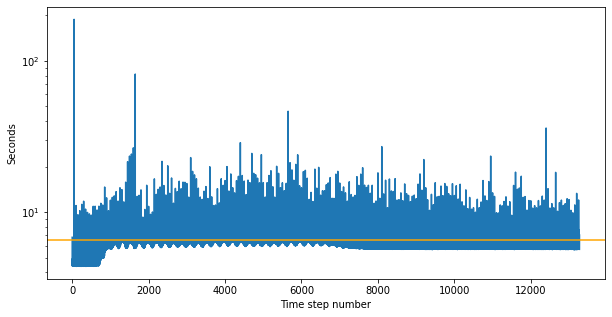

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda800e-9-tau30E-15-field7E8-CEP0.0-StH2/lambda1030e-9-tau30E-15-field1E8-CEP0.0-delay0e-15-StH


In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.semilogy(results_np[:,0], results_np[:,4])
plt.axhline(np.mean(results_np[:,4]), color="orange")
plt.xlabel("Time step number")
plt.ylabel("Seconds")
plt.savefig("DurationOfTimeStep.eps")
plt.show()
!pwd

# Fetch number of processes for this run

In [15]:
NumProcesses=int(libString.LookUpStringInFile(file, "processes").strip().split()[4])

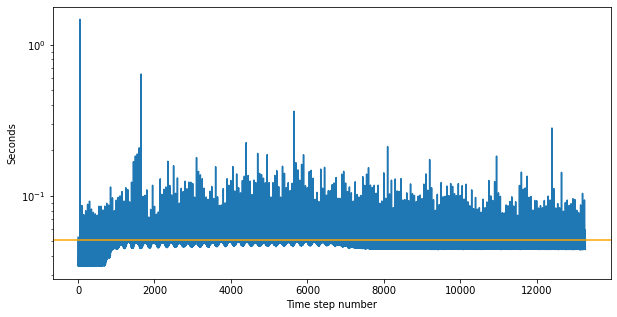

Average timestep duration for 128 threads:  0.0507589395858445


In [16]:
# Plot efficiency from that
plt.figure(figsize=(10,5))
plt.semilogy(results_np[:,0], results_np[:,4]/NumProcesses)
plt.axhline(np.mean(results_np[:,4]/NumProcesses), color="orange")
plt.xlabel("Time step number")
plt.ylabel("Seconds")
plt.savefig("DurationOfTimeStep-NormalizedToNumCores.eps")
plt.show()
print("Average timestep duration for "+str(NumProcesses)+" threads: ", np.mean(results_np[:,4]/NumProcesses))


# Database-wide analysis

In [17]:
DatabasePath=OctopusData+"/03-Bulk3D/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


In [18]:
data=pd.read_csv("SiComplete-2023-09-12-BiatriSrv-v2.4-WithToleranceOnField-WithAll-2.csv", "\t", header=2)
# data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)
# data=pd.read_csv("SiComplete-2023-04-30-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("alpha-SiO2-19-07-2023-AllFinishedRuns.csv", "\t", header=2)
# data=pd.read_csv("Database.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data=data.rename(columns={"##JobID": "JobID"})
datafull=data
data.dtypes

JobID                           float64
Machine                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
TimeStep                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64


## Overview of results

In [19]:
from octopus_slabs.Libs.libPlotting import MachineNameList, MachineNameHeader
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
print(len(Machine_data), len(data.DurationPerTimeStepLastRun), len(data.NumberOfProcesses))

2911 2911 2911


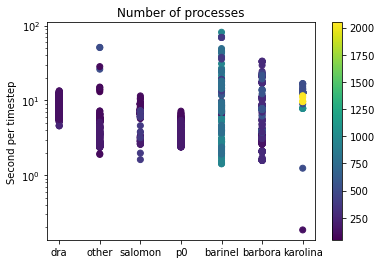

In [20]:
# %matplotlib
plt.figure()
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
plt.title("Number of processes")
plt.ylabel("Second per timestep")
plt.savefig("20230912-Overview.eps")
plt.show()

## Limiting result to precision of k-grid

In [21]:
data=datafull
# data=data[data.Functional==IndexFunctional["TB09"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data=data[data.kgrid==40]
# data=data[data.Machine==MachineNameHeader["karolina"]]
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2190,108831.0,4.0,20220210.0,40.0,0.434637,0.25,0.000002,1.118420e-14,3.000000e+09,0.0,...,0.0,5.605595e+26,5.001833e+40,5.012066e+40,1.0,0.0,1875.0,924.7404,21.628470,960.0
2191,107048.0,4.0,20220210.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.0,...,0.0,3.888609e+24,3.240066e+38,3.476877e+38,1.0,0.0,2000.0,924.7404,19.747960,960.0
2192,108832.0,4.0,20220210.0,40.0,0.434637,0.25,0.000002,1.118420e-14,9.000000e+09,0.0,...,0.0,4.725361e+28,4.225342e+42,4.225033e+42,1.0,0.0,1250.0,924.7404,31.085120,960.0
2193,597659.0,5.0,20220310.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,2.677097e+38,0.000000e+00,5.0,0.0,2000.0,0.0000,10.587850,576.0
2194,598340.0,5.0,20220320.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,2.005677e+38,0.000000e+00,5.0,0.0,3625.0,0.0000,11.292960,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2852,1567455.0,6.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,3.355341e+42,0.000000e+00,5.0,0.0,3625.0,0.0000,11.569400,2048.0
2854,1561286.0,6.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,1.536671e+42,0.000000e+00,5.0,0.0,4375.0,0.0000,9.659641,2048.0
2855,1567457.0,6.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,4.331984e+42,0.000000e+00,5.0,0.0,3875.0,0.0000,10.980270,2048.0
2856,1561289.0,6.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,4.724222e+42,0.000000e+00,5.0,0.0,4375.0,0.0000,9.765522,2048.0


In [22]:
from octopus_slabs.Libs.libPlotting import MachineNameList, MachineNameHeader
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
len(Machine_data)

240

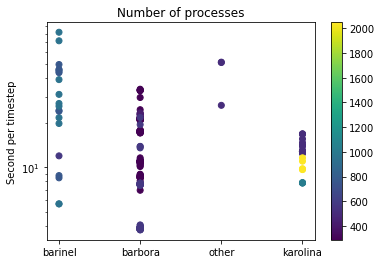

In [23]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
plt.colorbar()
plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep")
plt.title("Number of processes")
plt.savefig("20230912-Overview-k40.eps")
# plt.show()

## Analysis of Karolina

In [24]:
data=data[data.Machine==MachineNameHeader["karolina"]]
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2201,1640785.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,2.376803e+38,0.0,5.0,0.0,3250.00,0.0,12.772750,512.0
2202,1640649.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,3.204111e+38,0.0,5.0,0.0,3375.00,0.0,12.698240,512.0
2203,1640774.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,2.514440e+38,0.0,5.0,0.0,3375.00,0.0,12.697990,512.0
2204,1640782.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,1.502372e+38,0.0,5.0,0.0,3250.00,0.0,12.725020,512.0
2205,1640772.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,3.042319e+38,0.0,5.0,0.0,3375.00,0.0,12.670220,512.0
2206,1640778.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,1.394709e+38,0.0,5.0,0.0,3250.00,0.0,12.873580,512.0
2207,1640784.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,2.005418e+38,0.0,5.0,0.0,5241.25,0.0,12.352460,512.0
2208,1640775.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,2.199706e+38,0.0,5.0,0.0,3250.00,0.0,12.768050,512.0
2209,1640790.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,3.277580e+38,0.0,5.0,0.0,3375.00,0.0,12.679610,512.0
2210,1640780.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,1.244067e+38,0.0,5.0,0.0,3375.00,0.0,12.708560,512.0


In [25]:
from octopus_slabs.Libs.libPlotting import MachineNameList
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
data['Efficiency']=data.DurationPerTimeStepLastRun/data.NumberOfProcesses

/home/thibault.derrien/.local/lib/python3.6/site-packages/ipykernel_launcher.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """


In [26]:
len(Machine_data)

52

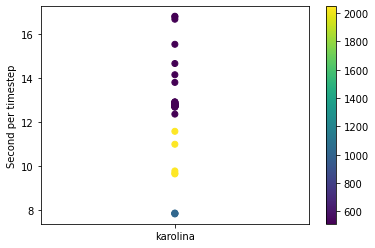

In [27]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep")
plt.savefig("20230912-Overview-k40-Karolina.eps")
plt.show()

In [28]:
DateOfProcessorCapping=20230201

In [29]:
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses,Efficiency
2201,1640785.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.376803e+38,0.0,5.0,0.0,3250.00,0.0,12.772750,512.0,0.024947
2202,1640649.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.204111e+38,0.0,5.0,0.0,3375.00,0.0,12.698240,512.0,0.024801
2203,1640774.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.514440e+38,0.0,5.0,0.0,3375.00,0.0,12.697990,512.0,0.024801
2204,1640782.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.502372e+38,0.0,5.0,0.0,3250.00,0.0,12.725020,512.0,0.024854
2205,1640772.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.042319e+38,0.0,5.0,0.0,3375.00,0.0,12.670220,512.0,0.024747
2206,1640778.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.394709e+38,0.0,5.0,0.0,3250.00,0.0,12.873580,512.0,0.025144
2207,1640784.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.005418e+38,0.0,5.0,0.0,5241.25,0.0,12.352460,512.0,0.024126
2208,1640775.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.199706e+38,0.0,5.0,0.0,3250.00,0.0,12.768050,512.0,0.024938
2209,1640790.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.277580e+38,0.0,5.0,0.0,3375.00,0.0,12.679610,512.0,0.024765
2210,1640780.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.244067e+38,0.0,5.0,0.0,3375.00,0.0,12.708560,512.0,0.024821


ValueError: time data '20230200' does not match format '%Y%m%d'

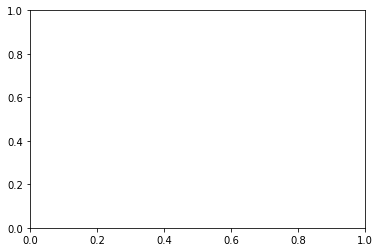

In [30]:
import matplotlib.dates as mdates
from datetime import datetime
fig, ax = plt.subplots()
dates = [datetime.strptime(str(int(date)), '%Y%m%d') for date in data.RunDate]
plt.scatter(data.RunDate, data.DurationPerTimeStepLastRun, c=data.RunDate-DateOfProcessorCapping)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y%m%d')) #this gonna be solved when NEW DB is ready
plt.colorbar()
plt.show()

We look at data prepared AFTER processor capping. 

In [31]:
data_tmp = data[data.RunDate >= DateOfProcessorCapping]
data_tmp2 = data_tmp[data_tmp.DurationPerTimeStepLastRun < 8] 

In [32]:
data_tmp

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses,Efficiency
2244,1737887.0,6.0,20230210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.600000e+09,0.0,...,0.0,7.015069e+38,0.0,5.0,0.0,3250.0,0.0,16.80671,512.0,0.032826
2245,1738063.0,6.0,20230210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.600000e+09,0.0,...,0.0,6.831269e+38,0.0,5.0,0.0,3125.0,0.0,16.78296,512.0,0.032779
2246,1738064.0,6.0,20230210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.600000e+09,0.0,...,0.0,4.839893e+38,0.0,5.0,0.0,3000.0,0.0,16.67126,512.0,0.032561
2247,1982079.0,6.0,20230720.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.600000e+09,0.0,...,0.0,1.062828e+39,0.0,5.0,0.0,4375.0,0.0,14.65516,512.0,0.028623


## Analysis of Barbora

In [33]:
from octopus_slabs.Libs.libPlotting import MachineNameList, MachineNameHeader

data=datafull
data=data[data.kgrid==40]
data=data[data.Machine==MachineNameHeader["barbora"]]

Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2193,597659.0,5.0,20220310.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.000000,...,0.0,0.000000e+00,2.677097e+38,0.000000e+00,5.0,0.0,2000.0,0.000,10.58785,576.0
2194,598340.0,5.0,20220320.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.000000,...,0.0,0.000000e+00,2.005677e+38,0.000000e+00,5.0,0.0,3625.0,0.000,11.29296,576.0
2647,586197.0,5.0,20211220.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.753982,...,0.0,2.473146e+27,1.773881e+41,1.773500e+41,1.0,0.0,1875.0,1153.011,22.65529,432.0
2648,528466.0,5.0,20210930.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.125664,...,0.0,2.018731e+27,1.447718e+41,1.447638e+41,1.0,0.0,1250.0,1153.011,33.23857,288.0
2649,586193.0,5.0,20211220.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.502655,...,0.0,2.374915e+27,1.703422e+41,1.703058e+41,1.0,0.0,1750.0,1153.011,23.09784,432.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2820,520137.0,5.0,20210920.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.471239,...,0.0,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.011,13.79488,576.0
2821,586196.0,5.0,20211220.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.691150,...,0.0,2.454259e+27,1.760294e+41,1.759957e+41,1.0,0.0,1750.0,1153.011,23.29073,432.0
2822,528467.0,5.0,20210930.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.188496,...,0.0,2.059679e+27,1.477081e+41,1.477002e+41,1.0,0.0,1250.0,1153.011,33.22149,288.0
2825,597660.0,5.0,20220310.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.785398,...,0.0,0.000000e+00,5.949421e+38,0.000000e+00,5.0,0.0,1500.0,0.000,19.40783,576.0


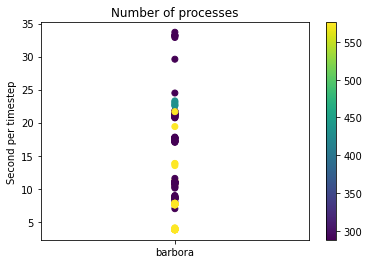

In [34]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep")
plt.title("Number of processes")
plt.savefig("20230912-Overview-k40-Barbora.eps")
plt.show()

In [35]:
# Create a reverse dictionnary
from octopus_slabs.Libs.libPlotting import IndexFunctional
IndexFunctional_rev = {value: key for key, value in IndexFunctional.items()}
print(IndexFunctional_rev)

{0: 'LDA', 3: 'TB09', 2: 'GGA', 1: 'MGGA'}


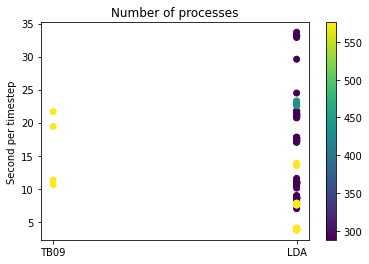

In [36]:
Functional_List = data.Functional.values.tolist()
Functional_Data = [IndexFunctional_rev[int(x)] for x in Functional_List]

# %matplotlib
plt.figure()
plt.scatter(Functional_Data, data.DurationPerTimeStepLastRun, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep")
plt.title("Number of processes")
plt.savefig("20230912-Overview-k40-Barbora-Functional.eps")
plt.show()

In [37]:
data = data[data.Functional == IndexFunctional["LDA"]]
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2647,586197.0,5.0,20211220.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.753982,...,0.0,2.473146e+27,1.773881e+41,1.773500e+41,1.0,0.0,1875.0,1153.011,22.65529,432.0
2648,528466.0,5.0,20210930.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.125664,...,0.0,2.018731e+27,1.447718e+41,1.447638e+41,1.0,0.0,1250.0,1153.011,33.23857,288.0
2649,586193.0,5.0,20211220.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.502655,...,0.0,2.374915e+27,1.703422e+41,1.703058e+41,1.0,0.0,1750.0,1153.011,23.09784,432.0
2650,527844.0,5.0,20210930.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.062832,...,0.0,1.986689e+27,1.424753e+41,1.424660e+41,1.0,0.0,1250.0,1153.011,33.68517,288.0
2651,528470.0,5.0,20210930.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.439823,...,0.0,2.309797e+27,1.656421e+41,1.656362e+41,1.0,0.0,1250.0,1153.011,32.89255,288.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,516077.0,5.0,20210910.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.157080,...,0.0,2.038333e+27,1.461907e+41,1.461694e+41,1.0,0.0,1500.0,1153.011,13.50284,576.0
2819,520136.0,5.0,20210920.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.314159,...,0.0,2.169291e+27,1.555847e+41,1.555605e+41,1.0,0.0,1500.0,1153.011,13.82624,576.0
2820,520137.0,5.0,20210920.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.471239,...,0.0,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.011,13.79488,576.0
2821,586196.0,5.0,20211220.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.691150,...,0.0,2.454259e+27,1.760294e+41,1.759957e+41,1.0,0.0,1750.0,1153.011,23.29073,432.0


### Effect of polarization angle

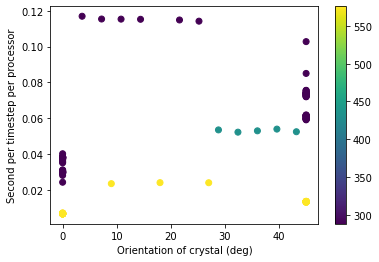

In [38]:
# %matplotlib
plt.figure()
plt.scatter(data.PolarizationAngle/np.pi*180., data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
plt.xlabel("Orientation of crystal (deg)")
plt.ylabel("Second per timestep per processor")
plt.savefig("20230912-Overview-k40-Barbora-LDA-Orientation.eps")
plt.show()

## Effect of choice of supercomputer

In [69]:
data = datafull #restoring initial database
# Select one direction of orientation
data = data[data.PolarizationAngle == 0]
# Select only LDA or TB09
data = data[data.Functional == IndexFunctional["LDA"]]
# Select the k-grid resolution
data = data[data.kgrid == 24]
# Select the real mesh resolution
data = data[data.realmesh > 0.43]
# Select single pulse runs
data = data[data.Efield2 < 0.1]

In [70]:
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
print(len(Machine_data), len(data.DurationPerTimeStepLastRun), len(data.NumberOfProcesses))

1463 1463 1463


In [71]:
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
0,4802615.0,1.0,20180510.0,24.0,0.434637,0.25,8.000000e-07,2.000000e-14,8.000000e+08,0.0,...,0.0,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.1474,9.509313,128.0
6,5026870.0,1.0,20180520.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.0,...,0.0,2.365529e+26,7.879395e+39,7.885098e+39,3.0,2.0,3475.0,1350.5610,6.184132,128.0
22,17401930.0,-1.0,20200100.0,24.0,0.434637,0.25,2.200000e-06,2.000000e-14,5.000000e+08,0.0,...,0.0,9.840502e+26,5.406782e+36,4.920251e+40,3.0,2.0,4125.0,1130.2070,5.203062,96.0
23,4968648.0,1.0,20180520.0,24.0,0.434637,0.25,8.000000e-07,2.000000e-14,5.500000e+08,0.0,...,0.0,6.532126e+25,3.256158e+39,3.266063e+39,3.0,2.0,3162.5,937.1474,6.774173,128.0
24,5027630.0,1.0,20180520.0,24.0,0.434637,0.25,4.000000e-07,2.000000e-14,5.000000e+09,0.0,...,0.0,2.000978e+28,1.001070e+42,1.000489e+42,3.0,2.0,2400.0,881.9875,8.923015,128.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2580,253867.0,4.0,20221120.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,1.730000e+09,0.0,...,0.0,9.045808e+26,1.813850e+40,1.816256e+40,1.0,0.0,5290.0,4117.9880,3.891844,768.0
2581,300868.0,4.0,20221200.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,2.000000e+09,0.0,...,0.0,1.735543e+27,3.479507e+40,3.484699e+40,1.0,0.0,5290.0,4117.9880,3.668010,768.0
2582,300931.0,4.0,20221210.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,4.000000e+09,0.0,...,0.0,1.590423e+28,3.193353e+41,3.193320e+41,1.0,0.0,5290.0,4117.9880,2.154329,768.0
2583,300932.0,4.0,20221220.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,5.000000e+09,0.0,...,0.0,2.914597e+28,5.851200e+41,5.852053e+41,1.0,0.0,4875.0,4117.9880,2.286738,768.0


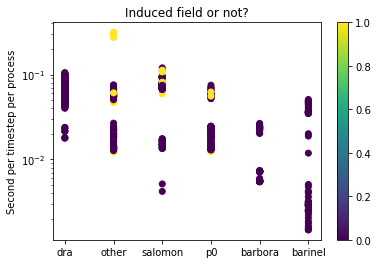

In [74]:
# %matplotlib
plt.figure()
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.InducedFields)
plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
plt.title("Induced field or not?")
plt.ylabel("Second per timestep per process")
plt.savefig("20230915-Overview-Filtered-InducedFields.eps")
plt.show()

In [77]:
data = data[data.InducedFields == 0]
data = data[data.MoveIon == 0]
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
print(len(Machine_data), len(data.DurationPerTimeStepLastRun), len(data.NumberOfProcesses))

1351 1351 1351


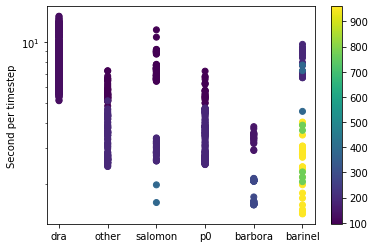

In [81]:
# %matplotlib
plt.figure()
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
# plt.title("Induced field or not?")
plt.ylabel("Second per timestep")
plt.savefig("20230915-Overview-Multimachines-Filtered.eps")
plt.show()

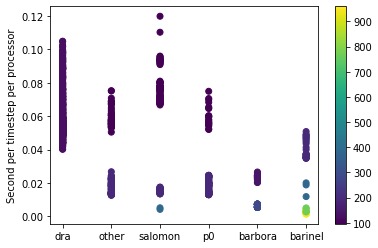

In [84]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.NumberOfProcesses)
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
# plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
# plt.title("Induced field or not?")
plt.ylabel("Second per timestep per processor")
plt.savefig("20230915-Overview-Multimachines-Filtered-PerProc.eps")
plt.show()